In [1]:
from pathlib import Path

DATA_DIR  = Path('/kaggle/input/datasets/zuzannasienko/speech-recognition-processed/speech_processed/data')
TRAIN_DIR = DATA_DIR / 'train'
VALID_DIR = DATA_DIR / 'valid'
TEST_DIR  = DATA_DIR / 'test'

In [2]:
import sys, os
REPO_PATH = '/kaggle/input/datasets/zuzannasienko/transformers-speech-recognition'
sys.path.insert(0, REPO_PATH)
os.chdir(REPO_PATH)

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from torch.utils.data import DataLoader

from data.utils import get_datasets, precompute_features
from data.dataset import CachedDataset
from models.train import train, predict
from models.evaluate import evaluate
from models.transformer import Transformer
from models.cnn_transformer import CNNTransformer
from models.utils import set_seed
from plots import plot_f1_training_curves, build_summary_df, plot_summary_table, plot_metrics_comparison, plot_confusion_matrix, plot_loss_and_f1_curves
EXPERIMENT_PATH = os.path.join(REPO_PATH, 'experiments/transformer_architecture')
sys.path.insert(0, EXPERIMENT_PATH)
from embeddings_plots import extract_embeddings, get_best_model, plot_tsne_comparison
from pooling_plots import extract_attention_weights, plot_attention_heatmap_comparison, plot_attention_profiles

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print('Using device:', device)

Using device: cuda


In [3]:
SEEDS = [0, 1, 2]
EPOCHS = 30
BATCH_SIZE = 64
LR = 3e-4
REPR = "mfcc"
D_MODEL = 128
N_HEADS = 4
N_LAYERS = [1, 2, 4, 6]
CLASS_NAMES = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go", "unknown", "silence"]

In [4]:
train_ds, valid_ds, test_ds = get_datasets(data_format=REPR, train_path=TRAIN_DIR, valid_path=VALID_DIR, test_path=TEST_DIR)
precompute_features(train_ds, Path('/kaggle/working/cache/train_mfcc'))
precompute_features(valid_ds, Path('/kaggle/working/cache/valid_mfcc'))
precompute_features(test_ds,  Path('/kaggle/working/cache/test_mfcc'))

train_cached = CachedDataset('/kaggle/working/cache/train_mfcc')
valid_cached = CachedDataset('/kaggle/working/cache/valid_mfcc')
test_cached  = CachedDataset('/kaggle/working/cache/test_mfcc')

  0%|          | 0/51486 [00:00<?, ?it/s]

Saved 51486 samples to /kaggle/working/cache/train_mfcc


  0%|          | 0/6828 [00:00<?, ?it/s]

Saved 6828 samples to /kaggle/working/cache/valid_mfcc


  0%|          | 0/6865 [00:00<?, ?it/s]

Saved 6865 samples to /kaggle/working/cache/test_mfcc


In [5]:
def run_nlayer_experiment(model_factory, n_layers, seeds, d_model=D_MODEL, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, device=device, model_name='Model'):
    """
    Trains and evaluates model_factory(nlayer) for each nlayer x seed combination.

    Args:
        model_factory: callable(nlayer: int) -> nn.Module
        n_layers: list of int
        seeds: list of int
        d_model: used only for divisibility check log
        model_name: used for print logs

    Returns:
        results[nlayer][seed] = {
            'history', 'valid_acc', 'valid_loss', 'valid_f1',
            'test_acc', 'test_macro_f1', 'test_weighted_f1',
            'test_cm', 'model'
        }
    """
    results = {}

    for nlayer in n_layers:
        results[nlayer] = {}
        for seed in seeds:
            print(f'\n[{model_name}] nlayer={nlayer} | seed={seed}')
            print('-' * 50)
            set_seed(seed)

            model = model_factory(nlayer).to(device)
            model, history = train(model, train_cached, valid_cached, epochs=epochs, batch_size=batch_size,
                                   lr=lr, device=str(device), verbose=True, verbose_interval=5)

            preds, labels = predict(model, test_cached, device=str(device), batch_size=batch_size)
            test_results  = evaluate(preds, labels, print_report=False)

            results[nlayer][seed] = {
                'history': history,
                'valid_acc': history['valid_acc'][-1],
                'valid_loss': history['valid_loss'][-1],
                'valid_f1': history['valid_f1'][-1],
                'test_acc': test_results['acc'],
                'test_macro_f1': test_results['macro_f1'],
                'test_weighted_f1': test_results['weighted_f1'],
                'test_cm': test_results['cm'],
                'model': model,
            }

    return results

In [6]:
def transformer_nlayer_factory(nlayer):
    return Transformer(n_features=40, n_timesteps=101, num_classes=12, d_model=D_MODEL, nhead=N_HEADS, num_layers=nlayer,
                       dropout=0.1, pooling='mean')

def cnn_transformer_nlayer_factory(nlayer):
    return CNNTransformer(n_features=40, n_timesteps=101, num_classes=12, base_channels=32, d_model=D_MODEL, nhead=N_HEADS,
                          num_layers=nlayer, dropout=0.1, pooling='mean')

### Transformer

In [9]:
transformer_nlayer_results = run_nlayer_experiment(model_factory=transformer_nlayer_factory, n_layers=N_LAYERS, seeds=SEEDS,
    d_model=D_MODEL, model_name='Transformer',)


[Transformer] nlayer=1 | seed=0
--------------------------------------------------
Epoch 5/30 | Train Loss: 0.3676 | Valid Loss: 0.3961 | Valid Acc: 0.8761 | Valid Macro F1: 0.8132
Epoch 10/30 | Train Loss: 0.2433 | Valid Loss: 0.3321 | Valid Acc: 0.8943 | Valid Macro F1: 0.8414
Epoch 15/30 | Train Loss: 0.1706 | Valid Loss: 0.3085 | Valid Acc: 0.9079 | Valid Macro F1: 0.8587
Epoch 20/30 | Train Loss: 0.1241 | Valid Loss: 0.3242 | Valid Acc: 0.9077 | Valid Macro F1: 0.8645
Epoch 25/30 | Train Loss: 0.0968 | Valid Loss: 0.3160 | Valid Acc: 0.9133 | Valid Macro F1: 0.8696
Epoch 30/30 | Train Loss: 0.0877 | Valid Loss: 0.3159 | Valid Acc: 0.9134 | Valid Macro F1: 0.8715
Best validation accuracy: 0.9136

[Transformer] nlayer=1 | seed=1
--------------------------------------------------
Epoch 5/30 | Train Loss: 0.3219 | Valid Loss: 0.3752 | Valid Acc: 0.8827 | Valid Macro F1: 0.8233
Epoch 10/30 | Train Loss: 0.2133 | Valid Loss: 0.3145 | Valid Acc: 0.9023 | Valid Macro F1: 0.8502
Epoch 15/

#### Transformer results

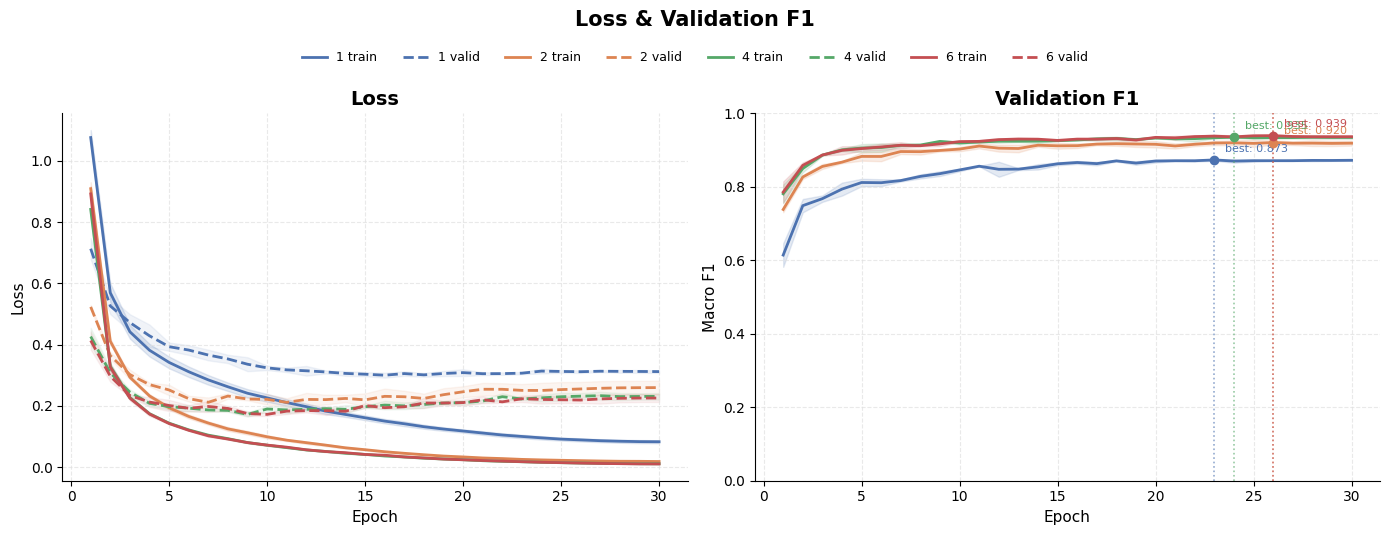

In [12]:
plot_loss_and_f1_curves(transformer_nlayer_results, group_name='')

In [13]:
summary_df = build_summary_df({
    f'nlayers={p}': {'mfcc': v}
    for p, v in transformer_nlayer_results.items()
})
plot_summary_table(summary_df)

,Model,Representation,Test Acc,Test Acc CV,Macro F1,Macro F1 CV,Weighted F1,Weighted F1 CV
0,nlayers=1,mfcc,0.9162 ± 0.0018,0.002,0.8533 ± 0.0051,0.006,0.9165 ± 0.0017,0.002
1,nlayers=2,mfcc,0.9480 ± 0.0037,0.004,0.8927 ± 0.0065,0.007,0.9491 ± 0.0037,0.004
2,nlayers=4,mfcc,0.9608 ± 0.0003,0.000,0.9126 ± 0.0031,0.003,0.9617 ± 0.0007,0.001
3,nlayers=6,mfcc,0.9622 ± 0.0009,0.001,0.9153 ± 0.0012,0.001,0.9632 ± 0.0011,0.001


,Model,Representation,Test Acc,Test Acc CV,Macro F1,Macro F1 CV,Weighted F1,Weighted F1 CV
0,nlayers=1,mfcc,0.9162 ± 0.0018,0.002,0.8533 ± 0.0051,0.006,0.9165 ± 0.0017,0.002
1,nlayers=2,mfcc,0.9480 ± 0.0037,0.004,0.8927 ± 0.0065,0.007,0.9491 ± 0.0037,0.004
2,nlayers=4,mfcc,0.9608 ± 0.0003,0.000,0.9126 ± 0.0031,0.003,0.9617 ± 0.0007,0.001
3,nlayers=6,mfcc,0.9622 ± 0.0009,0.001,0.9153 ± 0.0012,0.001,0.9632 ± 0.0011,0.001


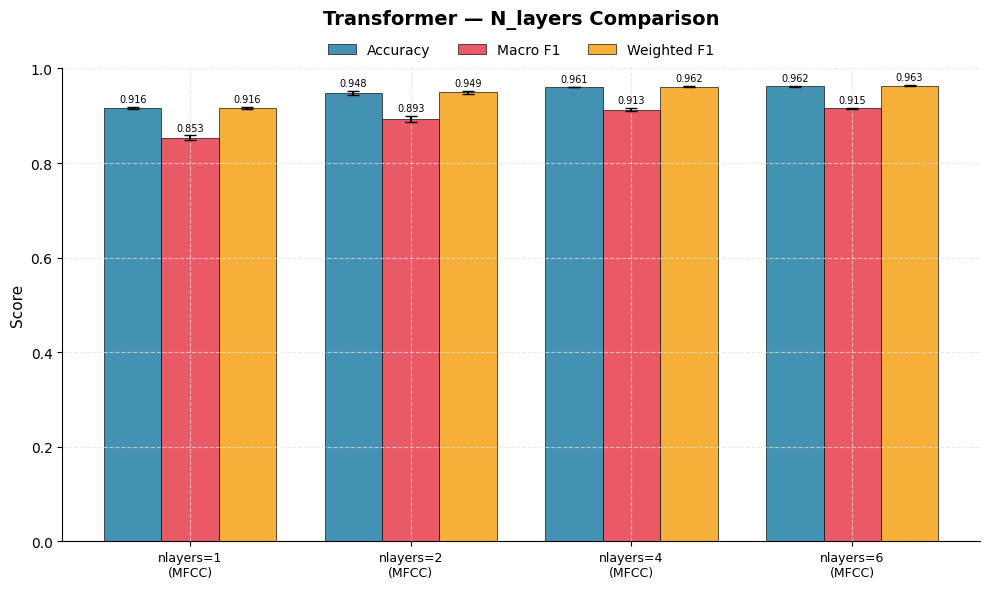

In [14]:
plot_metrics_comparison(summary_df, title='Transformer — N_layers Comparison')

In [20]:
embeddings_per_nlayer = {}
for nlayer in N_LAYERS:
    print(f'Extracting embeddings for nlayers={nlayer}...')
    model = get_best_model(transformer_nlayer_results, nlayer)
    embeddings, labels = extract_embeddings(model, test_cached, device)
    embeddings_per_nlayer[nlayer] = {'embs': embeddings, 'labels': labels}
    print(f'  -> shape: {embeddings.shape}')

Extracting embeddings for nlayers=1...
  -> shape: (6865, 128)
Extracting embeddings for nlayers=2...
  -> shape: (6865, 128)
Extracting embeddings for nlayers=4...
  -> shape: (6865, 128)
Extracting embeddings for nlayers=6...
  -> shape: (6865, 128)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


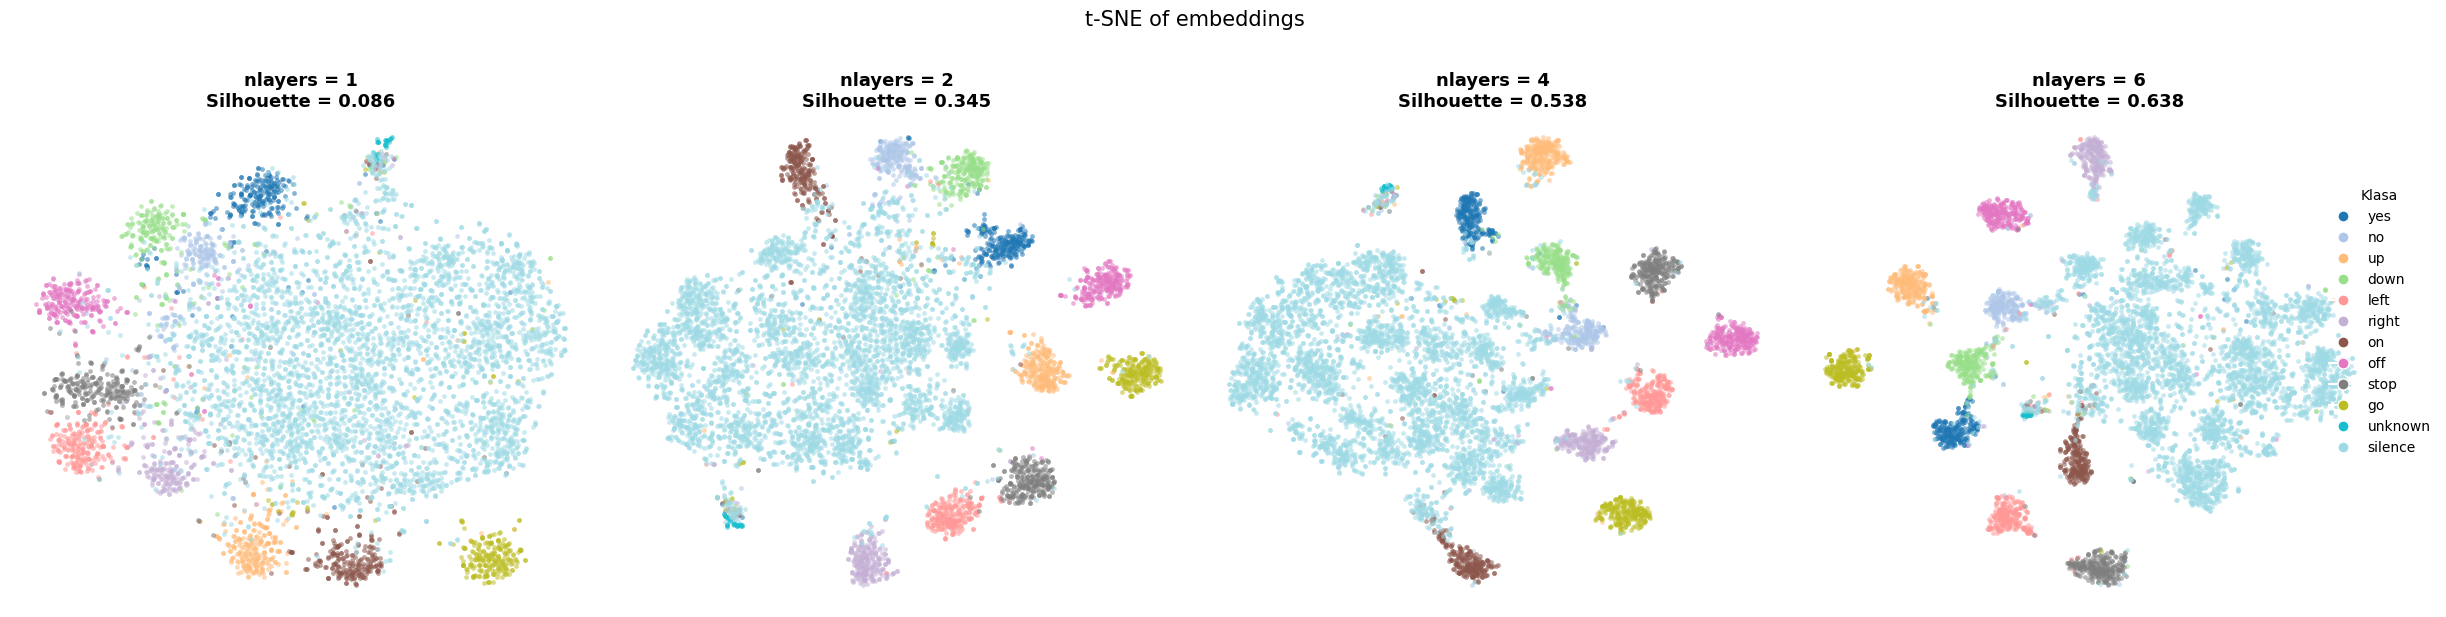

In [21]:
plot_tsne_comparison(embeddings_per_nlayer, CLASS_NAMES, key_label='nlayers')


 nlayers=1, seed=2, F1=0.8572


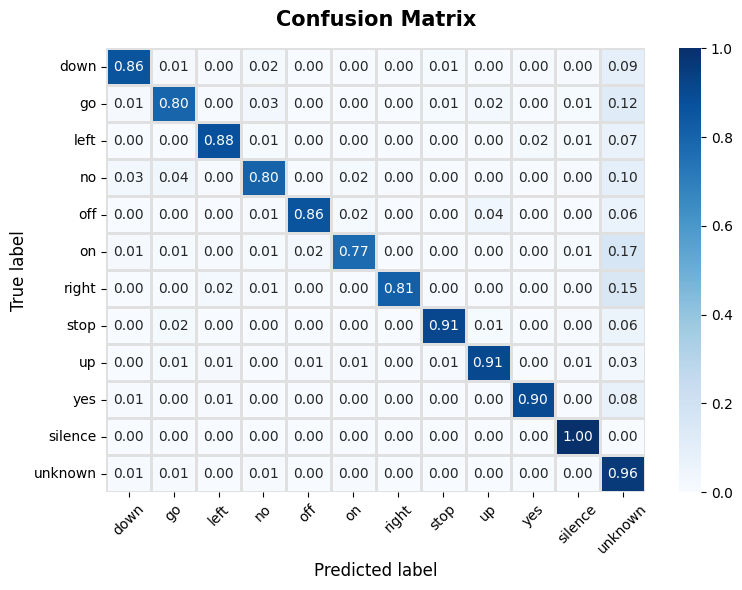


 nlayers=2, seed=1, F1=0.9014


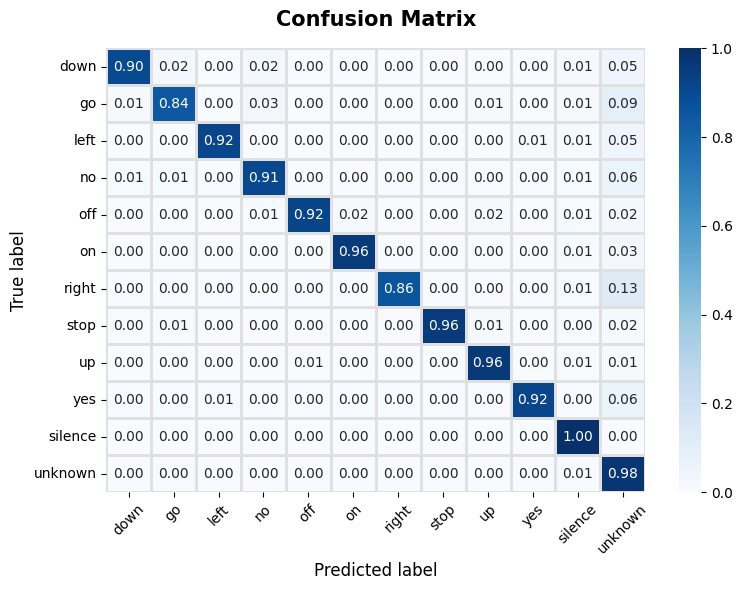


 nlayers=4, seed=1, F1=0.9152


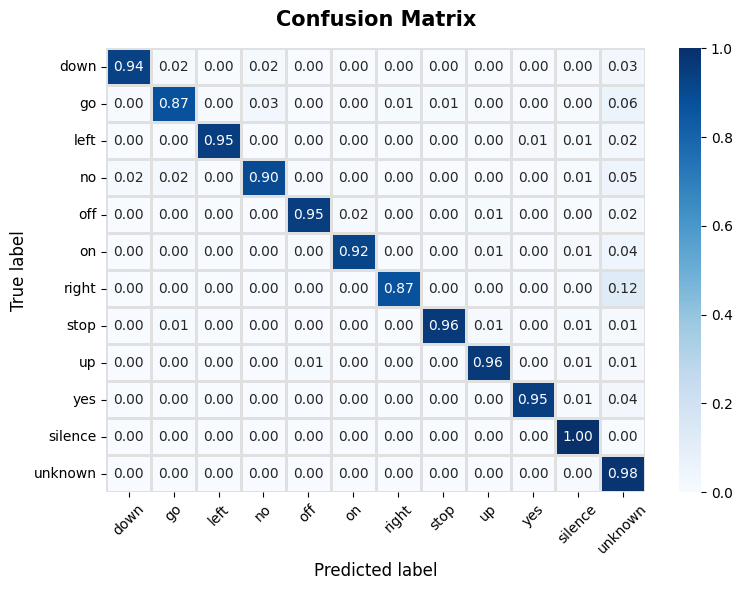


 nlayers=6, seed=0, F1=0.9163


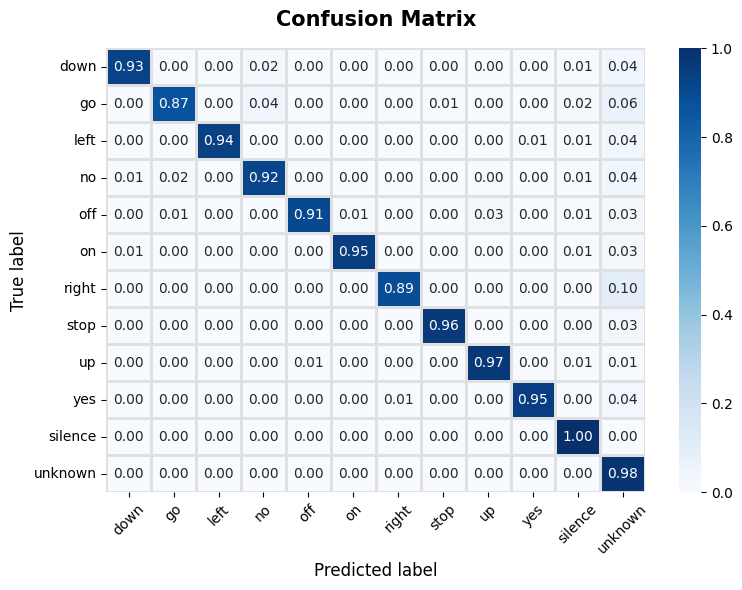

In [19]:
for nlayer in N_LAYERS:
    best_seed = max(transformer_nlayer_results[nlayer], key=lambda s: transformer_nlayer_results[nlayer][s]['test_macro_f1'])
    best_result = transformer_nlayer_results[nlayer][best_seed]
    print(f'\n nlayers={nlayer}, seed={best_seed}, F1={best_result["test_macro_f1"]:.4f}')
    plot_confusion_matrix(best_result['test_cm'])

### CNN Transformer

In [7]:
cnn_transformer_nlayer_results = run_nlayer_experiment(model_factory=cnn_transformer_nlayer_factory, n_layers=N_LAYERS,
    seeds=SEEDS, d_model=D_MODEL, model_name='CNNTransformer')


[CNNTransformer] nlayer=1 | seed=0
--------------------------------------------------
Epoch 5/30 | Train Loss: 0.1060 | Valid Loss: 0.1569 | Valid Acc: 0.9527 | Valid Macro F1: 0.9322
Epoch 10/30 | Train Loss: 0.0554 | Valid Loss: 0.2215 | Valid Acc: 0.9427 | Valid Macro F1: 0.9170
Epoch 15/30 | Train Loss: 0.0280 | Valid Loss: 0.1937 | Valid Acc: 0.9534 | Valid Macro F1: 0.9320
Epoch 20/30 | Train Loss: 0.0124 | Valid Loss: 0.2498 | Valid Acc: 0.9525 | Valid Macro F1: 0.9298
Epoch 25/30 | Train Loss: 0.0032 | Valid Loss: 0.2707 | Valid Acc: 0.9547 | Valid Macro F1: 0.9342
Epoch 30/30 | Train Loss: 0.0011 | Valid Loss: 0.2798 | Valid Acc: 0.9528 | Valid Macro F1: 0.9317
Best validation accuracy: 0.9547

[CNNTransformer] nlayer=1 | seed=1
--------------------------------------------------
Epoch 5/30 | Train Loss: 0.1233 | Valid Loss: 0.1984 | Valid Acc: 0.9405 | Valid Macro F1: 0.9082
Epoch 10/30 | Train Loss: 0.0614 | Valid Loss: 0.1942 | Valid Acc: 0.9445 | Valid Macro F1: 0.9195
Epo

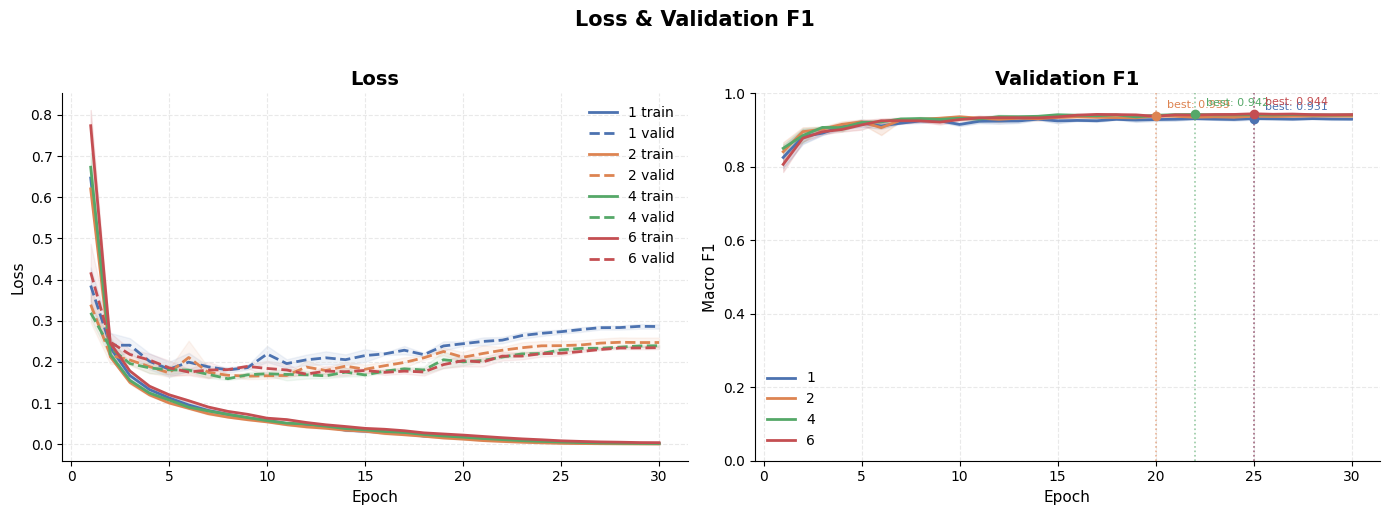

In [8]:
plot_loss_and_f1_curves(cnn_transformer_nlayer_results, group_name='')

In [9]:
summary_df = build_summary_df({
    f'nlayers={p}': {'mfcc': v}
    for p, v in cnn_transformer_nlayer_results.items()
})
plot_summary_table(summary_df)

,Model,Representation,Test Acc,Test Acc CV,Macro F1,Macro F1 CV,Weighted F1,Weighted F1 CV
0,nlayers=1,mfcc,0.9588 ± 0.0025,0.003,0.9366 ± 0.0027,0.003,0.9585 ± 0.0025,0.003
1,nlayers=2,mfcc,0.9704 ± 0.0015,0.002,0.9556 ± 0.0018,0.002,0.9703 ± 0.0015,0.002
2,nlayers=4,mfcc,0.9690 ± 0.0008,0.001,0.9554 ± 0.0014,0.001,0.9688 ± 0.0009,0.001
3,nlayers=6,mfcc,0.9681 ± 0.0019,0.002,0.9521 ± 0.0035,0.004,0.9679 ± 0.0019,0.002


,Model,Representation,Test Acc,Test Acc CV,Macro F1,Macro F1 CV,Weighted F1,Weighted F1 CV
0,nlayers=1,mfcc,0.9588 ± 0.0025,0.003,0.9366 ± 0.0027,0.003,0.9585 ± 0.0025,0.003
1,nlayers=2,mfcc,0.9704 ± 0.0015,0.002,0.9556 ± 0.0018,0.002,0.9703 ± 0.0015,0.002
2,nlayers=4,mfcc,0.9690 ± 0.0008,0.001,0.9554 ± 0.0014,0.001,0.9688 ± 0.0009,0.001
3,nlayers=6,mfcc,0.9681 ± 0.0019,0.002,0.9521 ± 0.0035,0.004,0.9679 ± 0.0019,0.002


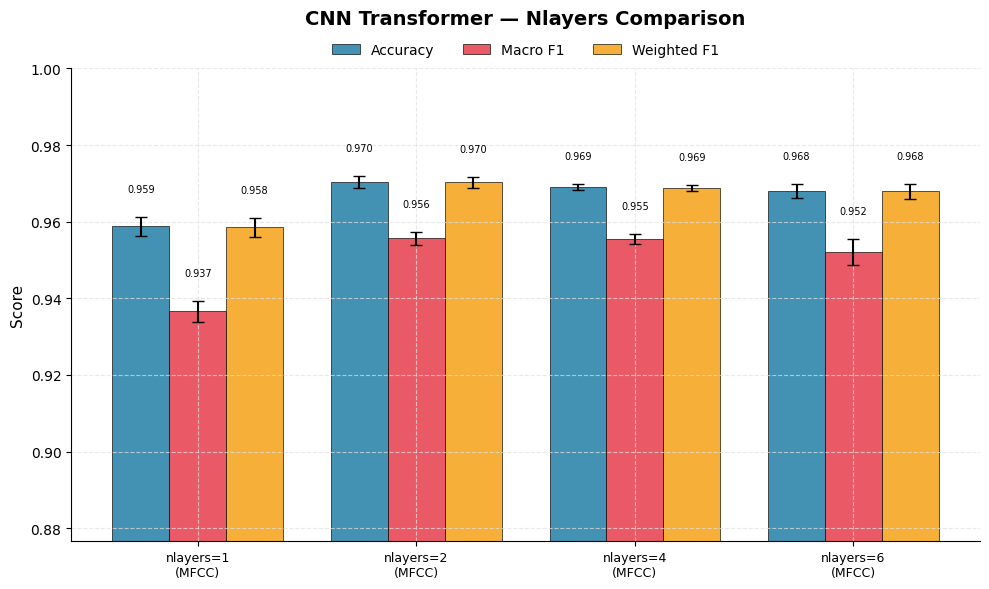

In [10]:
plot_metrics_comparison(summary_df, title='CNN Transformer — Nlayers Comparison')

In [12]:
embeddings_per_nlayer = {}
for nlayer in N_LAYERS:
    print(f'Extracting embeddings for nlayers={nlayer}...')
    model = get_best_model(cnn_transformer_nlayer_results, nlayer)
    embeddings, labels = extract_embeddings_cnn_transformer(model, test_cached, device)
    embeddings_per_nlayer[nlayer] = {'embs': embeddings, 'labels': labels}
    print(f'  -> shape: {embeddings.shape}')

Extracting embeddings for nlayers=1...
  -> shape: (6865, 128)
Extracting embeddings for nlayers=2...
  -> shape: (6865, 128)
Extracting embeddings for nlayers=4...
  -> shape: (6865, 128)
Extracting embeddings for nlayers=6...
  -> shape: (6865, 128)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


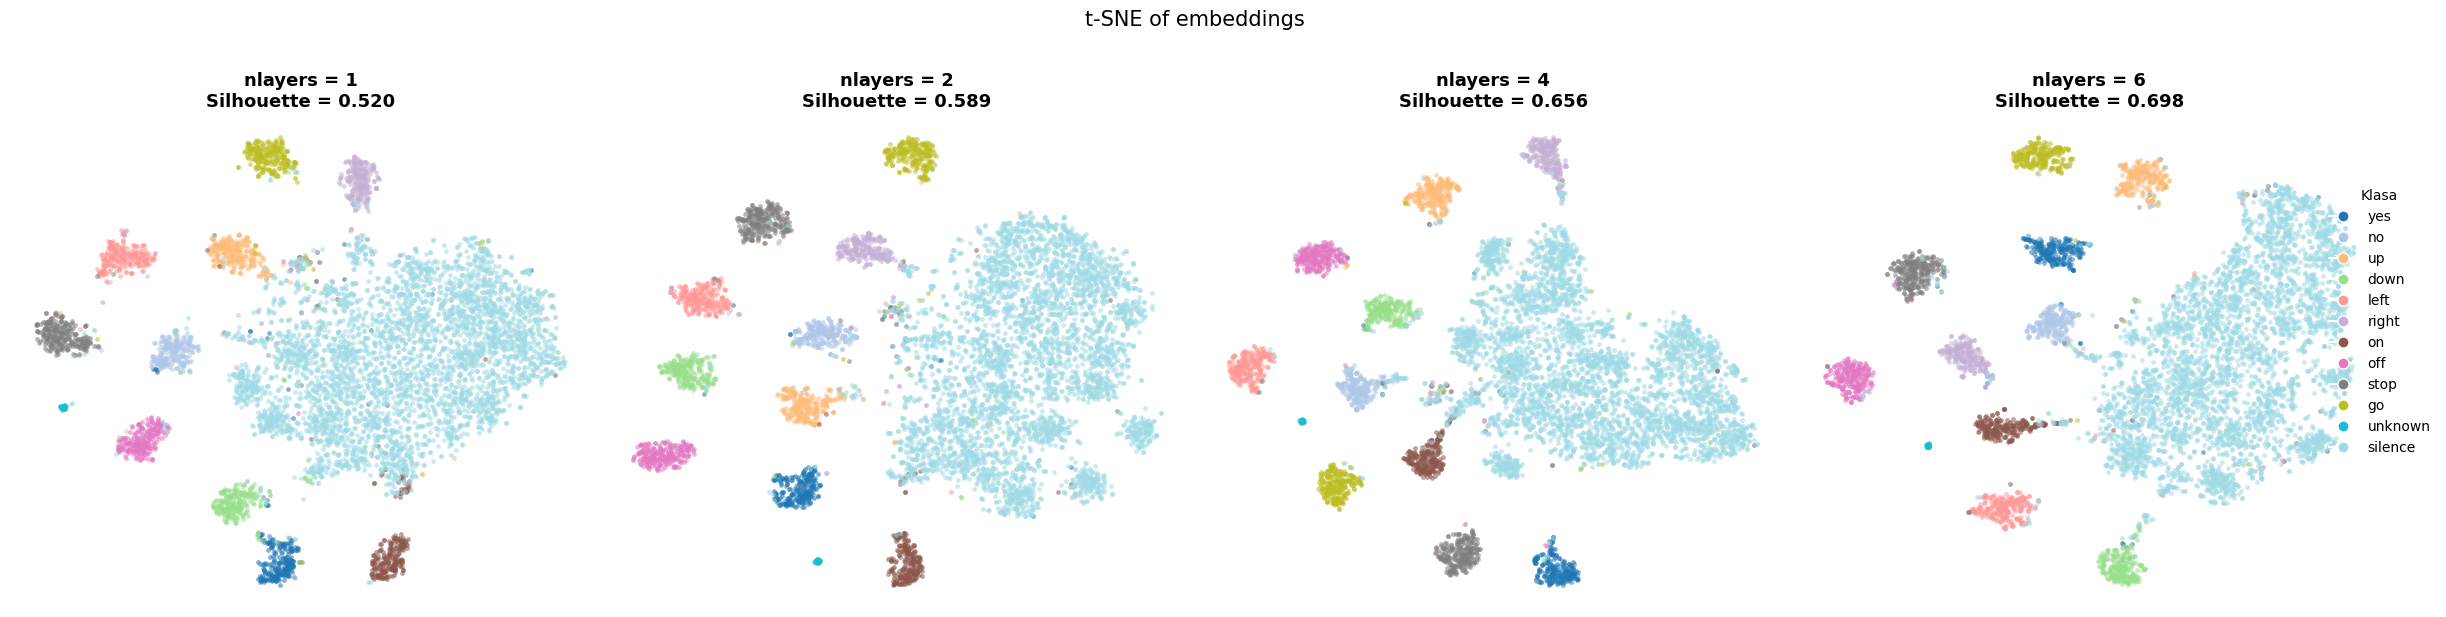

In [13]:
plot_tsne_comparison(embeddings_per_nlayer, CLASS_NAMES, key_label='nlayers')


 nlayers=1, seed=0, F1=0.9403


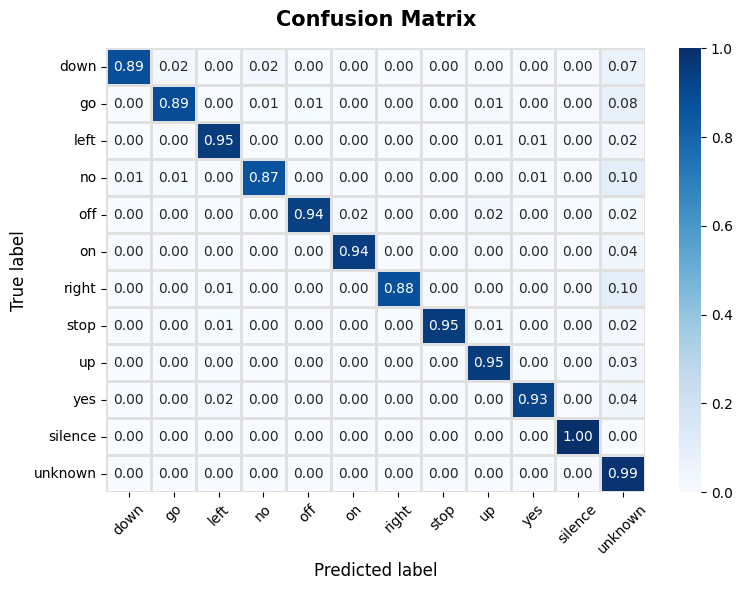


 nlayers=2, seed=1, F1=0.9582


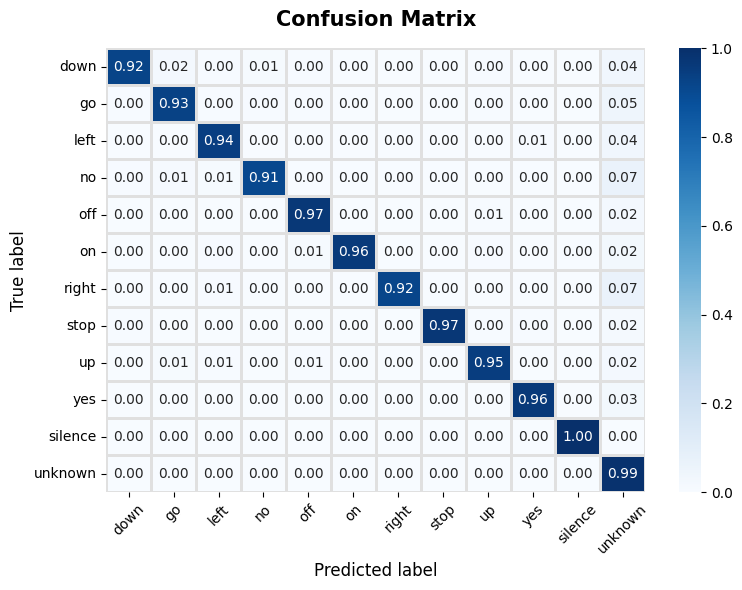


 nlayers=4, seed=2, F1=0.9566


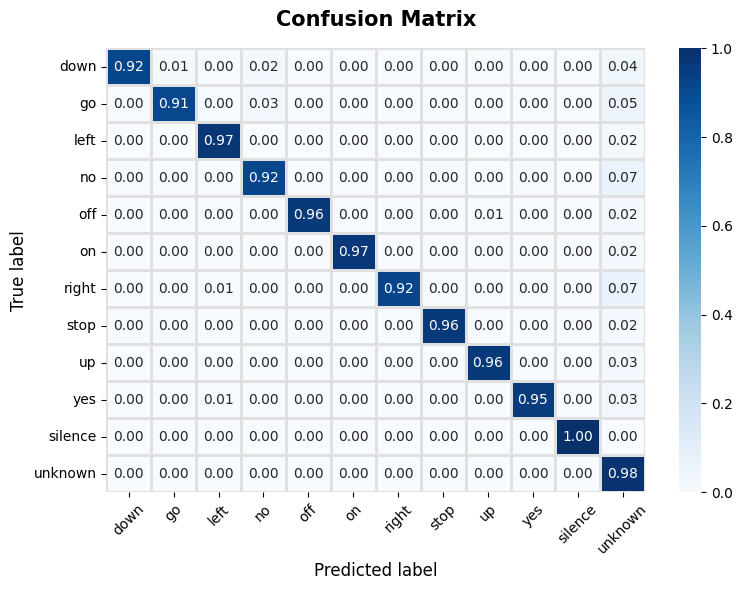


 nlayers=6, seed=2, F1=0.9570


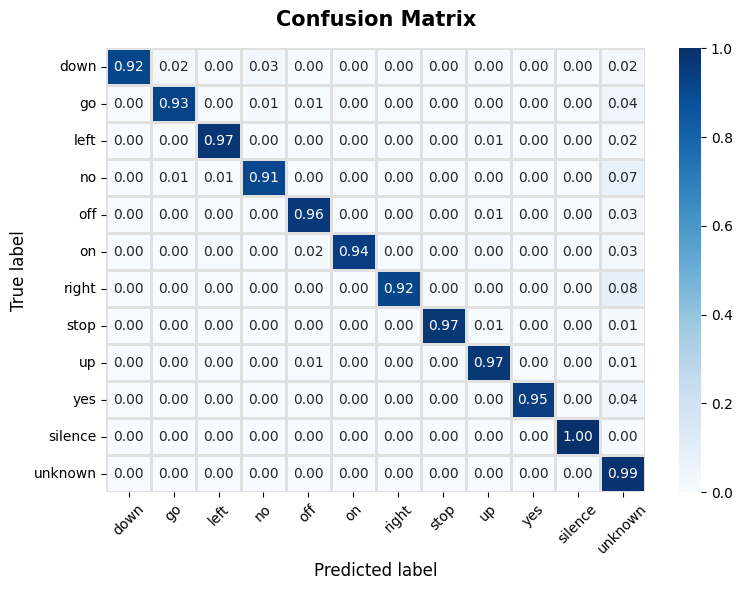

In [14]:
for nlayer in N_LAYERS:
    best_seed = max(cnn_transformer_nlayer_results[nlayer], key=lambda s: cnn_transformer_nlayer_results[nlayer][s]['test_macro_f1'])
    best_result = cnn_transformer_nlayer_results[nlayer][best_seed]
    print(f'\n nlayers={nlayer}, seed={best_seed}, F1={best_result["test_macro_f1"]:.4f}')
    plot_confusion_matrix(best_result['test_cm'])